# 03 - Exploratory Data Analysis

Numerical & categorical analysis, and the price relationships used to justify feature choices in `feature_engineering.py` / `preprocessing.py`.

In [1]:
import sys
sys.path.insert(0, '../src')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from data_loader import load_raw_data
from data_cleaning import clean_data
from feature_engineering import engineer_features

raw = load_raw_data('../data/raw/CAR DETAILS FROM CAR DEKHO.csv')
clean, _ = clean_data(raw)
df = engineer_features(clean)
df.shape

(3577, 13)

## Numerical analysis

In [2]:
summary = df[['selling_price', 'km_driven', 'car_age', 'mileage_per_year']].agg(
    ['mean', 'median', 'min', 'max', 'std']).T
summary

,mean,median,min,max,std
selling_price,473912.542074,350000.0,20000.0,8900000.0,509301.809816
km_driven,69250.545709,60000.0,1.0,806599.0,47579.940016
car_age,7.037462,7.0,0.0,28.0,4.251759
mileage_per_year,11628.724238,10000.0,0.2,140000.0,8955.064048


## Categorical analysis - most common brands, fuel types, transmissions

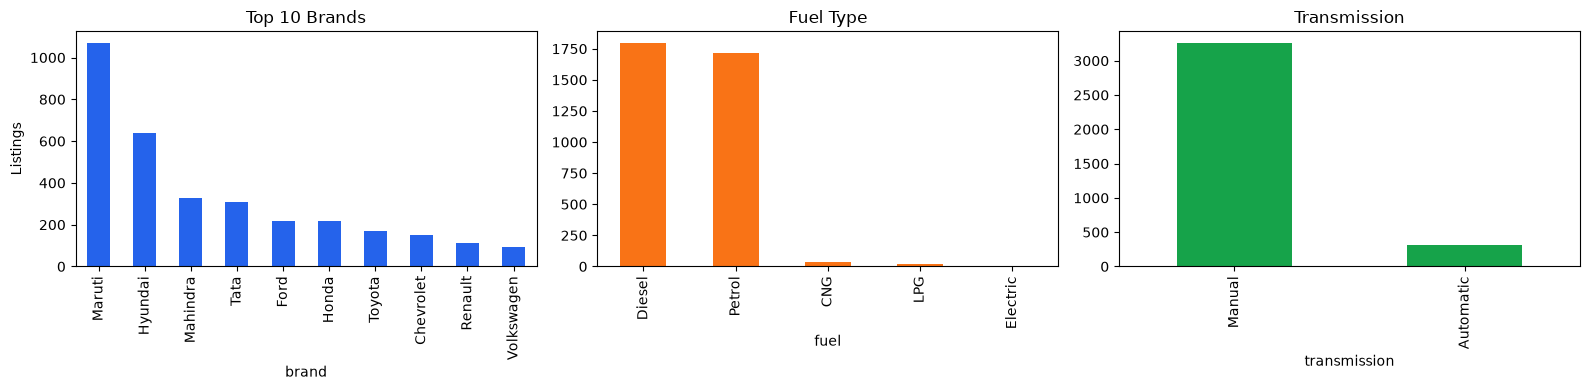

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df['brand'].value_counts().head(10).plot(kind='bar', ax=axes[0], color='#2563eb')
axes[0].set_title('Top 10 Brands'); axes[0].set_ylabel('Listings')
df['fuel'].value_counts().plot(kind='bar', ax=axes[1], color='#f97316')
axes[1].set_title('Fuel Type')
df['transmission'].value_counts().plot(kind='bar', ax=axes[2], color='#16a34a')
axes[2].set_title('Transmission')
plt.tight_layout()
plt.savefig('../reports/figures/categorical_overview.png', dpi=130)
plt.show()

## Price distribution

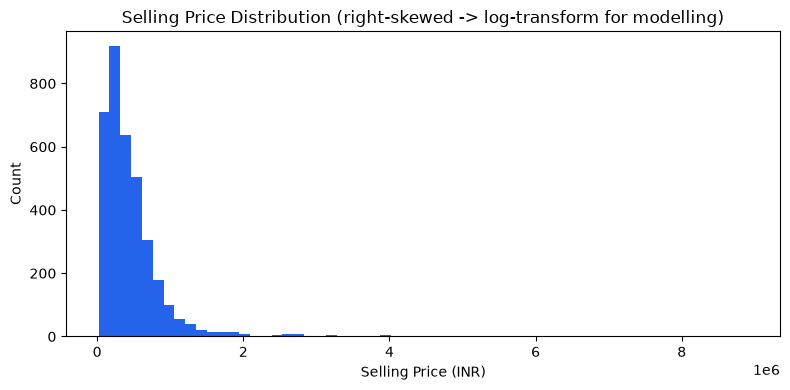

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['selling_price'], bins=60, color='#2563eb')
ax.set_xlabel('Selling Price (INR)'); ax.set_ylabel('Count')
ax.set_title('Selling Price Distribution (right-skewed -> log-transform for modelling)')
plt.tight_layout()
plt.savefig('../reports/figures/price_distribution.png', dpi=130)
plt.show()

## Relationships with price

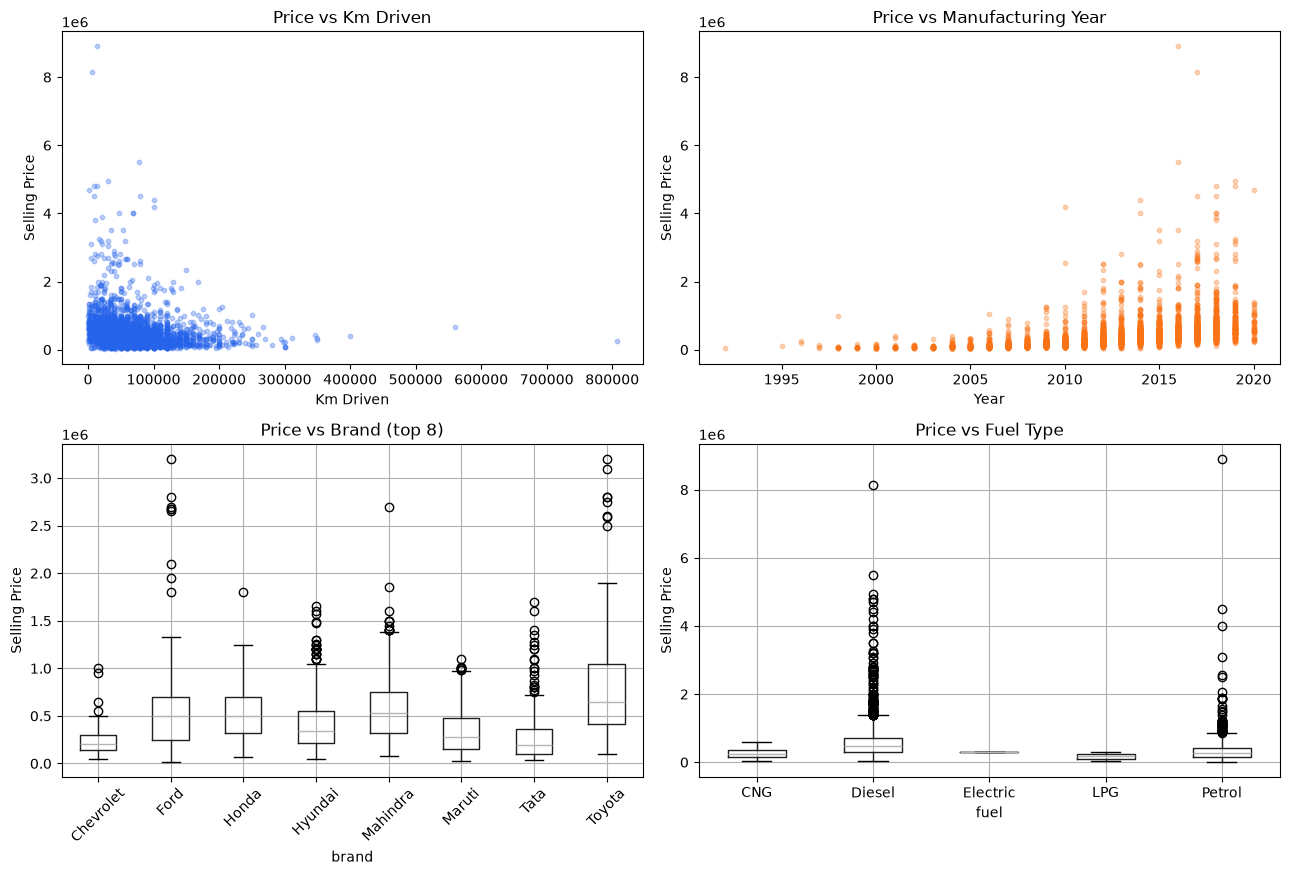

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0,0].scatter(df['km_driven'], df['selling_price'], alpha=0.3, s=10, color='#2563eb')
axes[0,0].set_xlabel('Km Driven'); axes[0,0].set_ylabel('Selling Price'); axes[0,0].set_title('Price vs Km Driven')

axes[0,1].scatter(df['year'], df['selling_price'], alpha=0.3, s=10, color='#f97316')
axes[0,1].set_xlabel('Year'); axes[0,1].set_ylabel('Selling Price'); axes[0,1].set_title('Price vs Manufacturing Year')

top_brands = df['brand'].value_counts().head(8).index
df[df['brand'].isin(top_brands)].boxplot(column='selling_price', by='brand', ax=axes[1,0], rot=45)
axes[1,0].set_title('Price vs Brand (top 8)'); axes[1,0].set_ylabel('Selling Price')

df.boxplot(column='selling_price', by='fuel', ax=axes[1,1])
axes[1,1].set_title('Price vs Fuel Type'); axes[1,1].set_ylabel('Selling Price')

plt.suptitle('')
plt.tight_layout()
plt.savefig('../reports/figures/price_relationships.png', dpi=130)
plt.show()

## Correlation matrix (numeric features)

In [6]:
numeric_cols = ['selling_price', 'year', 'car_age', 'km_driven', 'mileage_per_year']
corr = df[numeric_cols].corr()
corr

,selling_price,year,car_age,km_driven,mileage_per_year
selling_price,1.000000,0.424260,-0.424260,-0.187359,0.153843
year,0.424260,1.000000,-1.000000,-0.417490,0.334279
car_age,-0.424260,-1.000000,1.000000,0.417490,-0.334279
km_driven,-0.187359,-0.417490,0.417490,1.000000,0.469211
mileage_per_year,0.153843,0.334279,-0.334279,0.469211,1.000000


**Key findings that drove feature/model choices:**
- `car_age` correlates with price far more strongly than raw `km_driven` alone - both are kept,   plus their interaction `mileage_per_year`.
- Price is heavily right-skewed -> every model in `train_model.py` is trained on `log1p(price)`.
- A handful of luxury brands (Land Rover, Audi, BMW, Mercedes-Benz, Jaguar) sit far above the rest -   outliers that turn out to matter a lot for model comparison (see Model Performance page).